# 02. CatBoost: что даёт каждый слой признаков

Бустинг последовательно добавляет небольшие деревья решений, исправляющие ошибки предыдущих. CatBoost работает с категориями и умеет находить нелинейные сочетания. Сначала показываем модель на пяти исходных полях, затем постепенно добавляем признаки.

## Две версии одной модели

| Версия | Что видит модель |
|---|---|
| Базовые поля, 5 входов | Склад, артикул, два уровня категории и характеристика товара |
| С FE, 50 входов | Те же поля + календарь, история продаж, вчерашние остатки, общие продажи склада/товара и явные сочетания |

Внутри пары одинаковы обучающие строки, временные границы, функция потерь и правило выбора момента остановки. Меняется набор входов. FE — создание дополнительных признаков; все определения есть в [словаре](../features/FEATURES.md). Подготовка нулевых дней нужна обеим версиям и не считается различием между ними.

**Как читаем качество.** MAE — средняя абсолютная ошибка в штуках; меньше лучше. WAPE — суммарная абсолютная ошибка / суммарные продажи, в таблицах это доля. RMSE сильнее штрафует большие ошибки. RMSLE считает ошибку в логарифмической шкале. Смещение (bias) — средний прогноз минус факт; отрицательное значение означает недопрогноз. Валидация выбирает настройки, тест проверяет уже выбранную модель.

In [1]:
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'docs/datasets').is_dir())

import sys
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from features.catalog import LABELS, GROUP_LABELS, MODEL_LABELS, feature_label, identifier_label, display_ru
plt.rcParams.update({'date.autoformatter.month':'%m.%Y','date.autoformatter.day':'%d.%m',
                     'date.autoformatter.year':'%Y'})

RAW = ROOT / 'docs/datasets'
PROCESSED = ROOT / 'data/processed'
PROCESSED.mkdir(parents=True, exist_ok=True)
SEED = 42
pd.set_option('display.max_columns', 80)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})


from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_squared_log_error
OUT=ROOT/'data/artifacts/training'; MODELS=ROOT/'data/models'
OUT.mkdir(parents=True,exist_ok=True); MODELS.mkdir(parents=True,exist_ok=True)
manifest=json.loads((PROCESSED/'feature_manifest.json').read_text())
frames={s:pd.read_parquet(PROCESSED/f'{s}.parquet') for s in ['train','valid','test']}
FEATURE_SETS=manifest['feature_sets']
ALL_CATS=FEATURE_SETS['fe']['categorical']
for df in frames.values():
    for c in ALL_CATS: df[c]=df[c].astype('string').fillna('__MISSING__').astype(str)
assert frames['train'].date.max()<frames['valid'].date.min()<frames['test'].date.min()
assert set(FEATURE_SETS['base']['categorical'])<=set(ALL_CATS)

def metrics(y,pred):
    y=np.asarray(y,dtype='float64'); pred=np.maximum(np.asarray(pred,dtype='float64'),0)
    assert np.isfinite(pred).all() and len(y)==len(pred)
    return {'MAE':float(mean_absolute_error(y,pred)),
            'WAPE':float(np.abs(y-pred).sum()/y.sum()) if y.sum()>0 else np.nan,
            'RMSE':float(np.sqrt(mean_squared_error(y,pred))),
            'RMSLE':float(np.sqrt(mean_squared_log_error(y,pred))),
            'bias':float(np.mean(pred-y))}

def save_result(name,predictions,seconds,family,setting,columns,params):
    records=[]; output=[]
    for split,pred in predictions.items():
        pred=np.maximum(np.asarray(pred),0)
        records.append({'model':name,'family':family,'feature_set':setting,'feature_count':len(columns),
                        'split':split,**metrics(frames[split].quantity,pred),'fit_seconds':float(seconds)})
        p=frames[split][['date','pair_id','quantity']].copy(); p['prediction']=pred; p['split']=split; output.append(p)
    result=pd.DataFrame(records)
    result.to_csv(OUT/f'{name}_metrics.csv',index=False)
    pd.concat(output,ignore_index=True).to_parquet(PROCESSED/f'{name}_predictions.parquet',index=False)
    contract={'model':name,'family':family,'feature_set':setting,'features':columns,'parameters':params,
              'seed':SEED,'train_rows':len(frames['train']),
              'train_end':manifest['train_end'],'valid_start':manifest['valid_start'],'test_start':manifest['test_start']}
    (OUT/f'{name}_experiment.json').write_text(json.dumps(contract,indent=2,ensure_ascii=False))
    display_ru(result.round(5))
    return result

def show_pair(family):
    rows=pd.concat([pd.read_csv(OUT/f'{family}_{s}_metrics.csv') for s in ['base','fe']])
    display_ru(rows[['model','feature_count','split','MAE','WAPE','RMSE','bias']].round(5))
    for split in ['valid','test']:
        p=rows[rows.split.eq(split)].set_index('feature_set')
        gain=100*(1-p.loc['fe','MAE']/p.loc['base','MAE'])
        display(Markdown(f"**{MODEL_LABELS[split]}:** MAE меняется с {p.loc['base','MAE']:.4f} до {p.loc['fe','MAE']:.4f}; улучшение {gain:+.1f}%. Плюс означает уменьшение ошибки."))
    return rows

def fit_plot(y,pred,title,filename):
    fig,axes=plt.subplots(1,2,figsize=(13,4))
    z=pd.DataFrame({'actual':np.asarray(y),'predicted':np.maximum(pred,0)})
    z['bin']=pd.cut(z.predicted,[-.001,.1,.25,.5,1,2,4,8,16,np.inf])
    calibration=z.groupby('bin',observed=True).agg(actual=('actual','mean'),predicted=('predicted','mean'))
    axes[0].plot(calibration.predicted,calibration.actual,'o-')
    mx=max(calibration.predicted.max(),calibration.actual.max()); axes[0].plot([0,mx],[0,mx],'--',alpha=.5)
    axes[0].set(xlabel='Средний прогноз',ylabel='Средний факт',title='Калибровка: совпадает ли прогноз с фактом')
    residual=z.predicted-z.actual
    axes[1].hist(residual.clip(residual.quantile(.01),residual.quantile(.99)),bins=60)
    axes[1].set(xlabel='Прогноз минус факт: центральные 98%',title=title)
    plt.tight_layout(); plt.savefig(OUT/filename,dpi=160,bbox_inches='tight'); plt.show()

display_ru(pd.DataFrame([{'split':s,'rows':len(f),'date_min':f.date.min().date(),'date_max':f.date.max().date()} for s,f in frames.items()]))
print('Протокол: прогноз на день по данным, известным по конец предыдущего дня.')

,Период,Число строк,Первая дата,Последняя дата
0,Обучение,600000,2024-01-29,2026-06-05
1,Валидация,245758,2026-06-06,2026-07-03
2,Тест,245784,2026-07-04,2026-07-31


Протокол: прогноз на день по данным, известным по конец предыдущего дня.


## Добавляем группы по одной

Все варианты используют одинаковые параметры: до 250 деревьев глубины 6, функцию потерь MAE, один seed и одну валидацию. Обучение останавливается, если качество не улучшается 35 шагов. Сравнение с удалением или добавлением групп часто называют ablation; здесь это просто проверка вклада признаков.

Порядок: исходные категории → календарь → история и общие продажи → остатки → явные сочетания. Для основной пары берём первую и последнюю версии. Функцию потерь между строками не меняем: разницу можно связать с набором входов. Вклад отдельной группы зависит от порядка её добавления.

MAE учит модель предсказывать условную медиану. При множестве нулевых дней она может занижать суммарный объём; поэтому рядом обязательно смотрим RMSE и смещение.

In [2]:
from catboost import CatBoostRegressor
G=manifest['groups']; identity=manifest['categorical']
calendar=identity+G['calendar']
history=calendar+G['history']+G['aggregate']
stock_features=history+G['stock']
variants={'identity_only':identity,'calendar_identity':calendar,'history_aggregate':history,
          'history_stock':stock_features,'full_crosses':stock_features+manifest['crosses']}
params={'iterations':250,'depth':6,'learning_rate':.08,'loss_function':'MAE','eval_metric':'MAE',
        'random_seed':SEED,'thread_count':8,'l2_leaf_reg':5,'bootstrap_type':'Bernoulli','subsample':.8,
        'max_ctr_complexity':1,'one_hot_max_size':20,'allow_writing_files':False}
trials=[]; candidates={}
for variant,columns in variants.items():
    cats=[c for c in columns if c in ALL_CATS]
    start=time.perf_counter(); model=CatBoostRegressor(**params)
    model.fit(frames['train'][columns],frames['train'].quantity,cat_features=cats,
              eval_set=(frames['valid'][columns],frames['valid'].quantity),early_stopping_rounds=35,verbose=False)
    elapsed=time.perf_counter()-start
    valid_pred=np.maximum(model.predict(frames['valid'][columns]),0)
    row={'variant':variant,'objective':'MAE','feature_count':len(columns),'trees':model.tree_count_,
         'fit_seconds':elapsed,**metrics(frames['valid'].quantity,valid_pred)}
    trials.append(row); candidates[variant]=(model,columns,valid_pred,elapsed)
    print(f"{MODEL_LABELS[variant]}: MAE={row['MAE']:.4f}; {elapsed:.1f} с",flush=True)
trials=pd.DataFrame(trials); trials['MAE_change_vs_previous']=trials.MAE.diff()
trials.to_csv(OUT/'catboost_ablation.csv',index=False); display_ru(trials.round(5))
trained={}
for setting,variant in [('base','identity_only'),('fe','full_crosses')]:
    model,columns,valid_pred,elapsed=candidates[variant]
    predictions={'valid':valid_pred,'test':np.maximum(model.predict(frames['test'][columns]),0)}
    name=f'catboost_{setting}'
    save_result(name,predictions,elapsed,'catboost',setting,columns,params)
    model.save_model(str(MODELS/f'{name}.cbm'))
    (MODELS/f'{name}_features.json').write_text(json.dumps({'features':columns,'categorical':[c for c in columns if c in ALL_CATS]},indent=2))
    importance=pd.DataFrame({'feature':columns,'importance':model.get_feature_importance()}).sort_values('importance',ascending=False)
    importance.to_csv(OUT/f'{name}_importance.csv',index=False)
    trained[setting]=(model,importance,predictions)
show_pair('catboost')

Только исходные категории: MAE=0.3755; 31.9 с


+ Календарь: MAE=0.3765; 10.1 с


+ История и агрегаты: MAE=0.2785; 30.5 с


+ Остатки: MAE=0.2769; 24.3 с


+ Явные сочетания: MAE=0.2757; 33.8 с


...

,Модель,Семейство модели,Признак = set,Число признаков,Период,"MAE, шт.","WAPE, доля","RMSE, шт.",RMSLE,"Смещение, шт.","Время обучения, с"
0,CatBoost: с FE,CatBoost,С добавленными признаками,50,Валидация,0.27571,0.72345,0.86714,0.31520,-0.15804,33.80744
1,CatBoost: с FE,CatBoost,С добавленными признаками,50,Тест,0.28647,0.71667,0.88596,0.31793,-0.15993,33.80744


,Модель,Число признаков,Период,"MAE, шт.","WAPE, доля","RMSE, шт.","Смещение, шт."
0,CatBoost: базовые поля,5,Валидация,0.37550,0.98530,1.33920,-0.35822
1,CatBoost: базовые поля,5,Тест,0.39333,0.98402,1.39636,-0.37683
0,CatBoost: с FE,50,Валидация,0.27571,0.72345,0.86714,-0.15804
1,CatBoost: с FE,50,Тест,0.28647,0.71667,0.88596,-0.15993


**Валидация:** MAE меняется с 0.3755 до 0.2757; улучшение +26.6%. Плюс означает уменьшение ошибки.

**Тест:** MAE меняется с 0.3933 до 0.2865; улучшение +27.2%. Плюс означает уменьшение ошибки.

,model,Семейство модели,Набор входов,feature_count,split,MAE,WAPE,RMSE,RMSLE,bias,fit_seconds
0,catboost_base,catboost,base,5,valid,0.375502,0.985295,1.339202,0.450459,-0.358216,31.854201
1,catboost_base,catboost,base,5,test,0.393332,0.984017,1.396362,0.461185,-0.376833,31.854201
0,catboost_fe,catboost,fe,50,valid,0.275712,0.723452,0.867143,0.315200,-0.158038,33.807440
1,catboost_fe,catboost,fe,50,test,0.286468,0.716671,0.885962,0.317929,-0.159928,33.807440


## Важность и ошибки

Важность показывает, насколько модель использовала признак в деревьях. Связанные лаги могут делить один сигнал, а их важность не равна причинному эффекту. Основное подтверждение пользы FE — парная метрика выше, а не высота столбика важности.

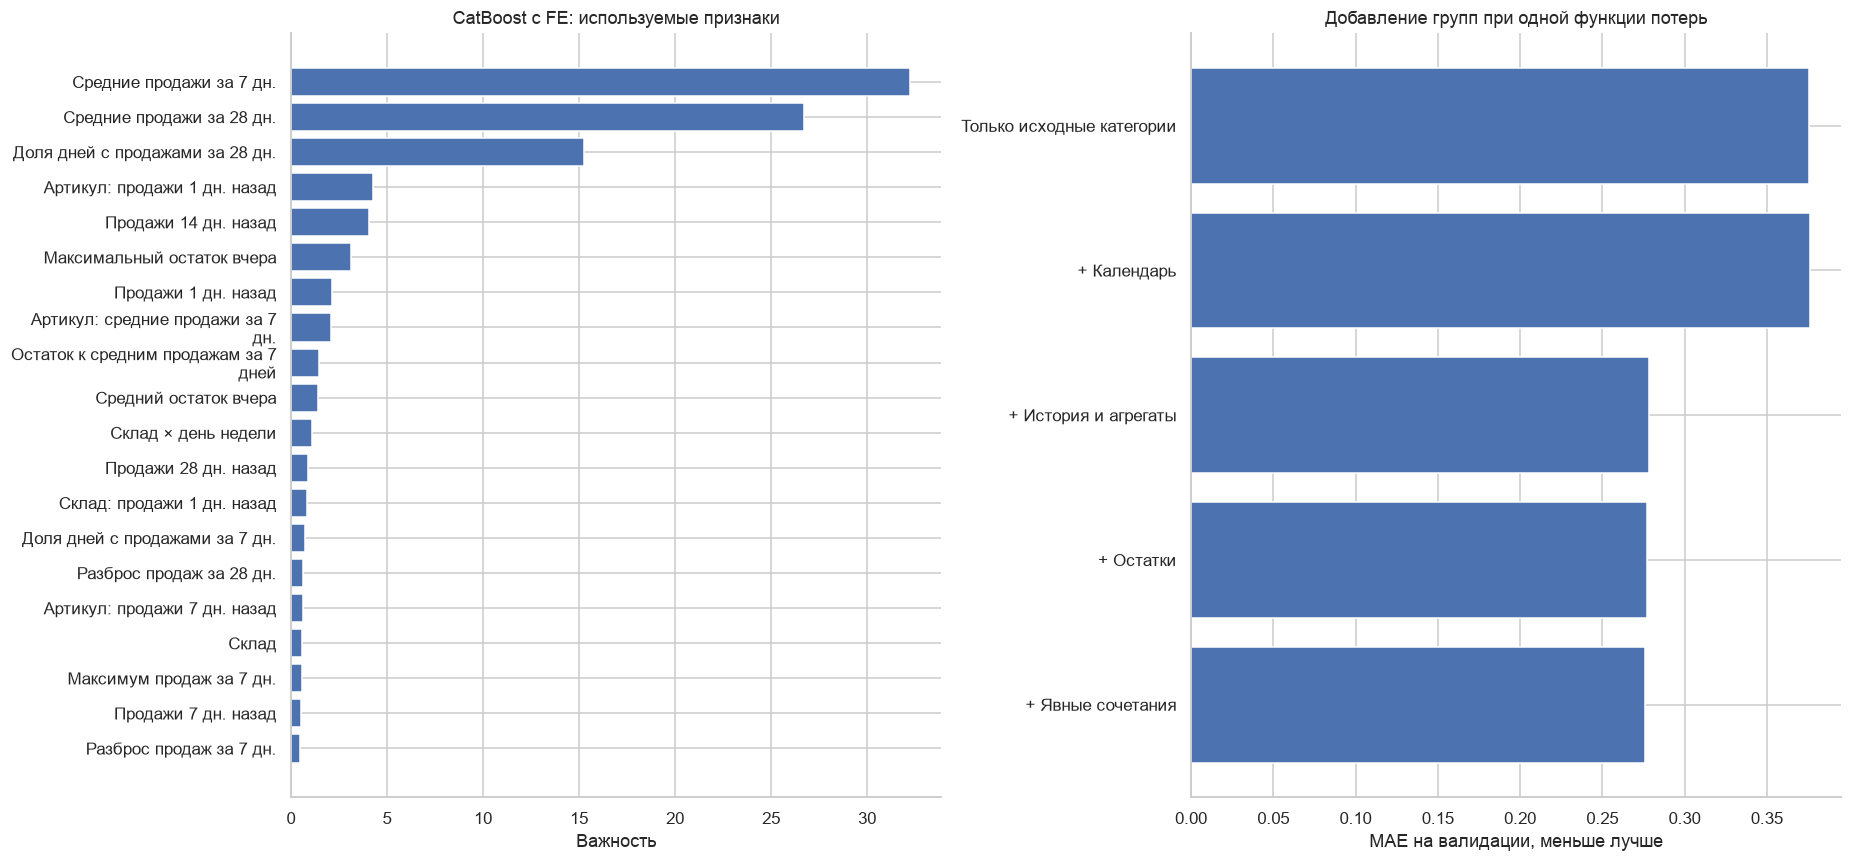

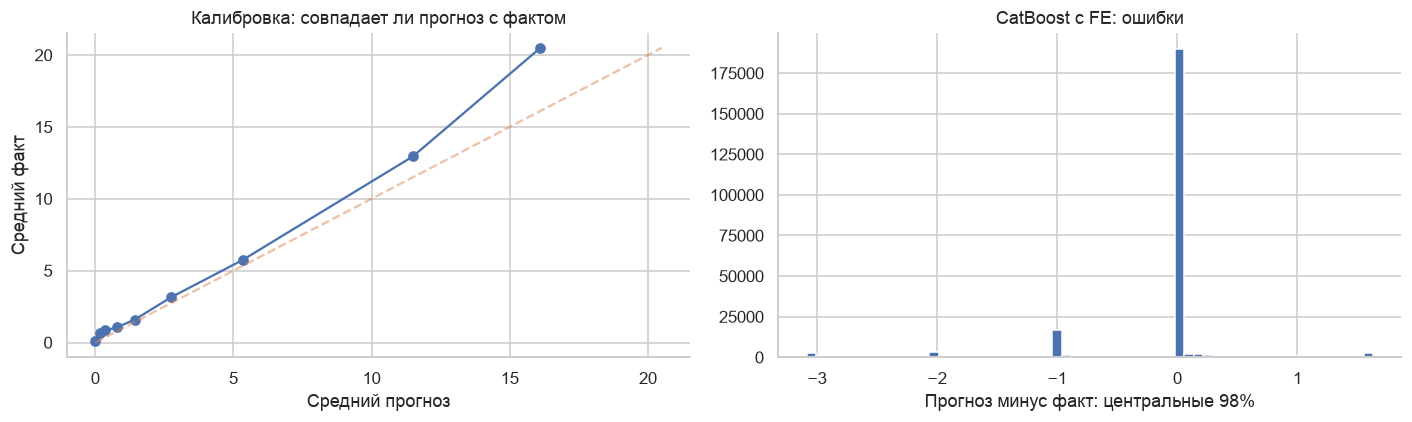

In [3]:
fig,axes=plt.subplots(1,2,figsize=(17,8))
importance=trained['fe'][1].head(20).sort_values('importance')
axes[0].barh([feature_label(c,width=32) for c in importance.feature],importance.importance)
axes[0].set(title='CatBoost с FE: используемые признаки',xlabel='Важность')
axes[1].barh([MODEL_LABELS[x] for x in trials.variant],trials.MAE)
axes[1].invert_yaxis(); axes[1].set(title='Добавление групп при одной функции потерь',xlabel='MAE на валидации, меньше лучше')
plt.tight_layout(); plt.savefig(OUT/'03_catboost_features.png',dpi=160,bbox_inches='tight'); plt.show()
fit_plot(frames['test'].quantity,trained['fe'][2]['test'],'CatBoost с FE: ошибки','04_catboost_calibration.png')